# SI 671 — RQ2 Temporal Demand Profile Mining

**Yiwu Gu | 2025 NYC Yellow Taxi**  

**Primary clustering specification.** We use a minimum annual pickup threshold of 1,000 to reduce instability caused by extremely sparse taxi zones. This retains 227 zones covering approximately 99.978% of the included pickup records. PCA preserves at least 90% of the variance in normalized temporal profiles, and K-means identifies three interpretable clusters. The original all-zone result and alternative sparsity thresholds are retained as sensitivity analyses.

The authoritative reproducible algorithms are in `src/temporal/`. Run the three commands below in your **repo-root terminal** before inspecting results in this notebook.

```bash
python -m src.temporal.build_profiles --threads 4
python -m src.temporal.cluster_profiles --variance 0.90 --min-pickups 1000
python -m src.temporal.plot_results
```

Study design: 263 valid geographic taxi zones; use Pickup-valid records, not `valid_od`; 168D Monday=0...Sunday=6 mean weekday-hour counts; exclude 2025-03-09 and 2025-11-02 (DST dates); row-normalize to study shape; fit PCA and K-means; select K using silhouette with small-cluster guard.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import Image, display
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
TABLES=ROOT/'results/temporal/tables'
FIGS=ROOT/'results/temporal/figures'
assert TABLES.exists(), 'Run build_profiles and cluster_profiles first.'
meta=json.loads((TABLES/'profile_metadata.json').read_text())
cluster_meta=json.loads((TABLES/'clustering_metadata.json').read_text())
print('Source metadata:',meta)
print('Clustering metadata:',cluster_meta)


Source metadata: {'year': 2025, 'n_zones': 263, 'n_day_hour_features': 168, 'total_included_pickups': 48350453, 'days_by_weekday_monday_0': {'0': 52, '1': 52, '2': 53, '3': 52, '4': 52, '5': 52, '6': 50}, 'excluded_dst_dates': ['2025-03-09', '2025-11-02'], 'filters': 'cleaned pickup-valid; 2025 pickup timestamps; TLC zones except 264,265; no valid_od condition', 'raw': 'mean pickup count per occurrence of given weekday/hour', 'normalized': 'divide each 168D raw vector by its sum; zero vectors stay zero and are not clustered', 'time': 'NYC naive local wall clock; DST dates excluded for descriptive clustering'}
Clustering metadata: {'chosen_k': 3, 'k_selection_rule': 'highest silhouette with min cluster size >=5', 'pca_n_components': 14, 'pca_cumulative_variance': 0.9019150912702804, 'n_zones_clustered': 227, 'n_zones_unassigned': 36, 'min_pickups': 1000, 'seed_ari_pairwise_mean': 1.0, 'seed_ari_pairwise_min': 1.0, 'raw_vs_normalized_ari': 0.2159777685300422, 'interpretation': 'Full-year

## 1. Sanity checks: 263 × 168 profiles

Raw = mean demand per day-of-week and hour; Normalized = within-zone relative shape. The latter is our primary K-means input.

In [2]:
raw=pd.read_csv(TABLES/'zone_profiles_raw.csv')
norm=pd.read_csv(TABLES/'zone_profiles_normalized.csv')
diag=pd.read_csv(TABLES/'zone_profile_diagnostics.csv')
assert raw.shape==norm.shape==(263,169)
print('Active zones:',int((diag.total_pickups>0).sum()))
print('Normalized row sums:',norm.drop(columns='zone_id').sum(axis=1).describe())
display(diag.sort_values('total_pickups',ascending=False).head(10))


Active zones: 260
Normalized row sums: count    263.000000
mean       0.988593
std        0.106394
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
dtype: float64


,zone_id,total_pickups,active_slots,mean_pickups_per_calendar_day,status
236,237,2116752,168,5831.272727,eligible
160,161,2082627,168,5737.264463,eligible
131,132,2050146,168,5647.785124,eligible
235,236,1866071,168,5140.691460,eligible
185,186,1534734,168,4227.917355,eligible
229,230,1509216,168,4157.619835,eligible
161,162,1501775,168,4137.121212,eligible
141,142,1381989,168,3807.132231,eligible
169,170,1288503,168,3549.595041,eligible
233,234,1287310,168,3546.308540,eligible


## 2. PCA and choosing K

Silhouette is evaluated **in the same retained PCA space as K-means**. K is an analytical choice, not ground-truth class count.

Selected K: 3 PCA components: 14


,k,silhouette,inertia,min_cluster_size,max_cluster_size,passes_size_rule,selected
0,2,0.296237,0.275378,90,137,True,False
1,3,0.298611,0.215125,20,128,True,True
2,4,0.253926,0.183822,16,86,True,False
3,5,0.261635,0.164808,2,84,False,False
4,6,0.245807,0.147589,2,74,False,False
5,7,0.240105,0.135697,3,74,False,False
6,8,0.246054,0.123479,1,72,False,False


,cluster_id,n_zones,median_annual_pickups,mean_annual_pickups,peak_day_of_week,peak_hour,weekend_share
0,0,128,9573.5,22025.828125,1.0,7.0,0.306821
1,1,79,244266.0,509243.113924,5.0,23.0,0.309290
2,2,20,69122.0,264514.000000,6.0,0.0,0.475096


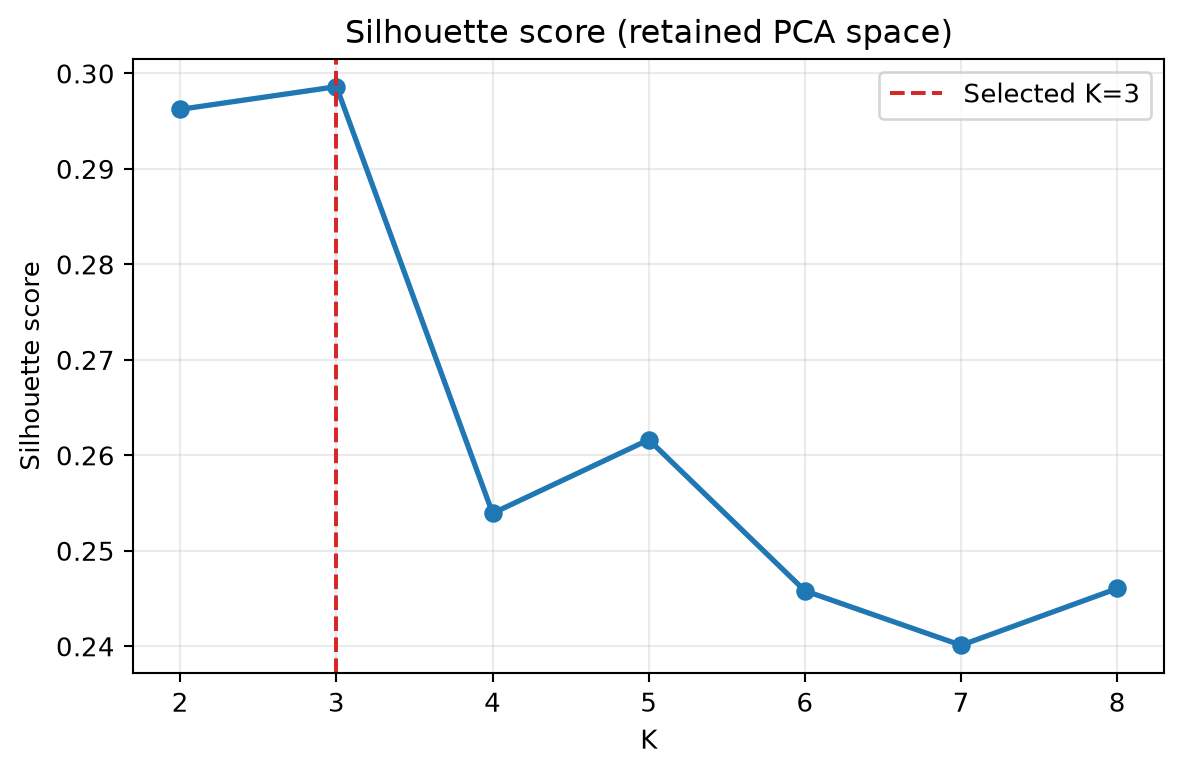

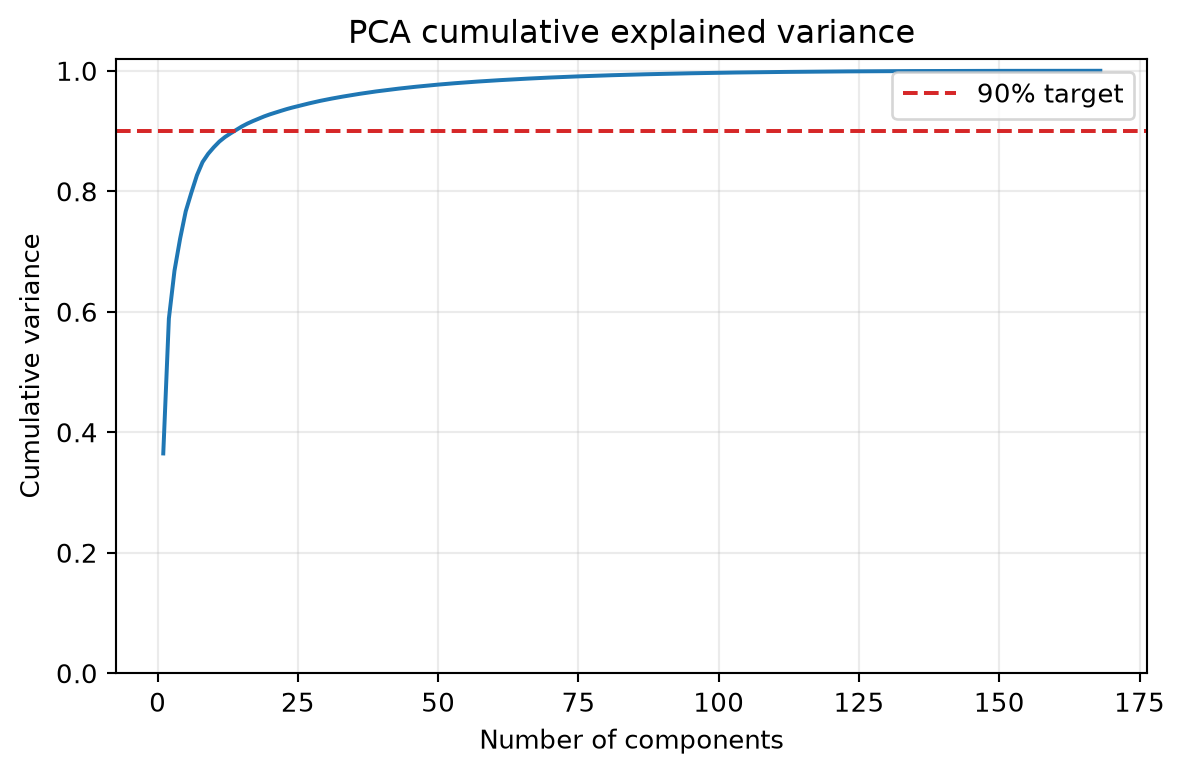

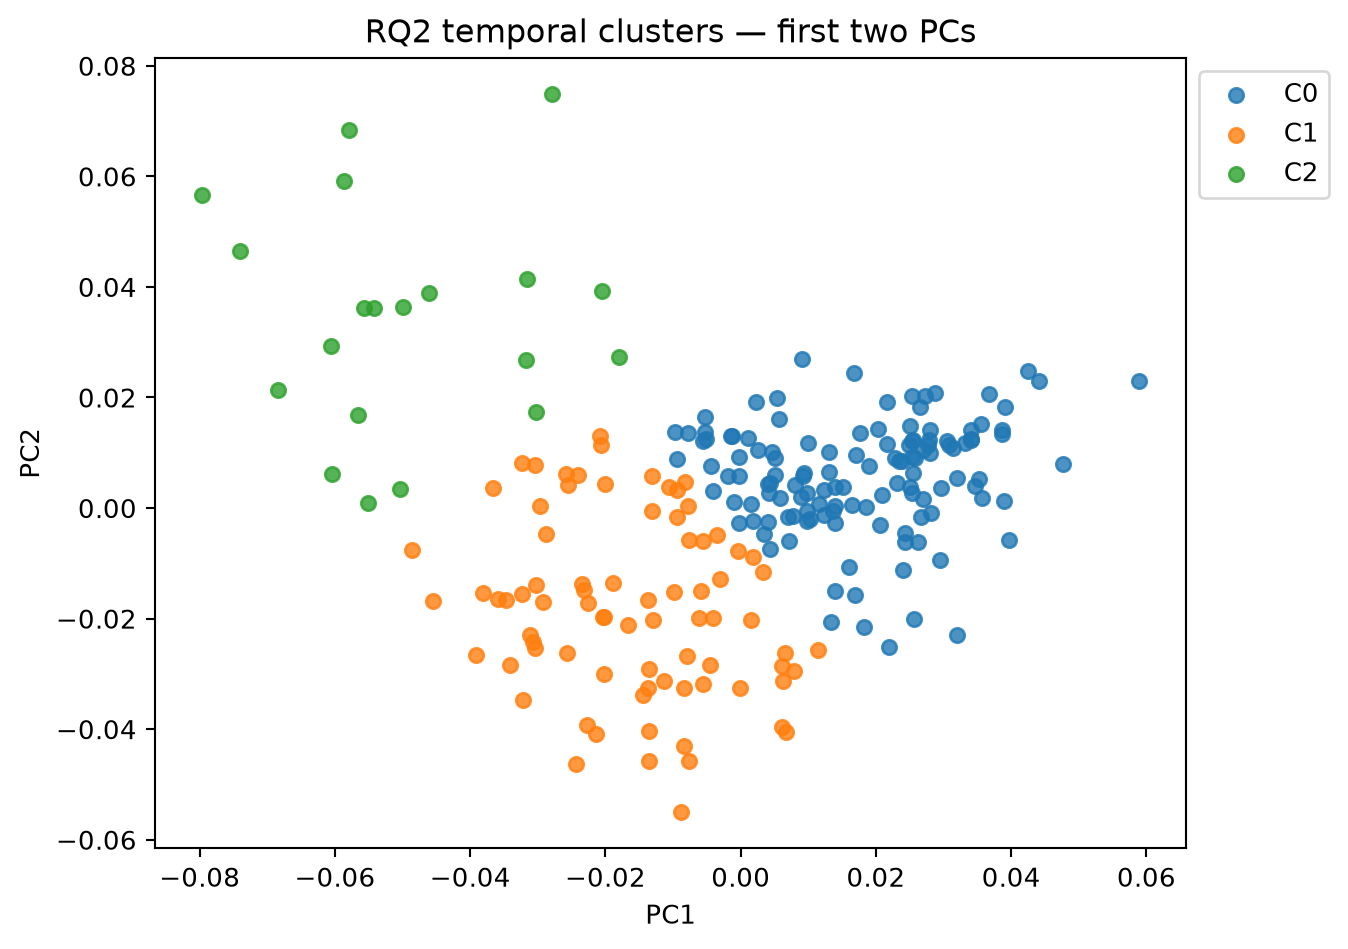

In [3]:
ks=pd.read_csv(TABLES/'k_selection.csv')
summary=pd.read_csv(TABLES/'cluster_summary.csv')
print('Selected K:',cluster_meta['chosen_k'],'PCA components:',cluster_meta['pca_n_components'])
display(ks)
display(summary)
for name in ['rq2_silhouette_k.png','rq2_pca_variance.png','rq2_pca_scatter.png']:
    p=FIGS/name
    if p.exists(): display(Image(filename=str(p),width=650))


## 3. Interpret cluster-average temporal profiles

Cluster IDs are arbitrary. Name them only after inspecting the profiles, peak hours, weekly structure and representative locations.

,zone_id,cluster_id,distance_to_centroid,Borough,Zone
0,76,0,0.008513,Brooklyn,East New York
1,89,0,0.009834,Brooklyn,Flatbush/Ditmas Park
2,169,0,0.011275,Bronx,Mount Hope
3,65,1,0.011813,Brooklyn,Downtown Brooklyn/MetroTech
4,137,1,0.012682,Manhattan,Kips Bay
5,50,1,0.014375,Manhattan,Clinton West
6,256,2,0.013467,Brooklyn,Williamsburg (South Side)
7,112,2,0.025351,Brooklyn,Greenpoint
8,37,2,0.026116,Brooklyn,Bushwick South


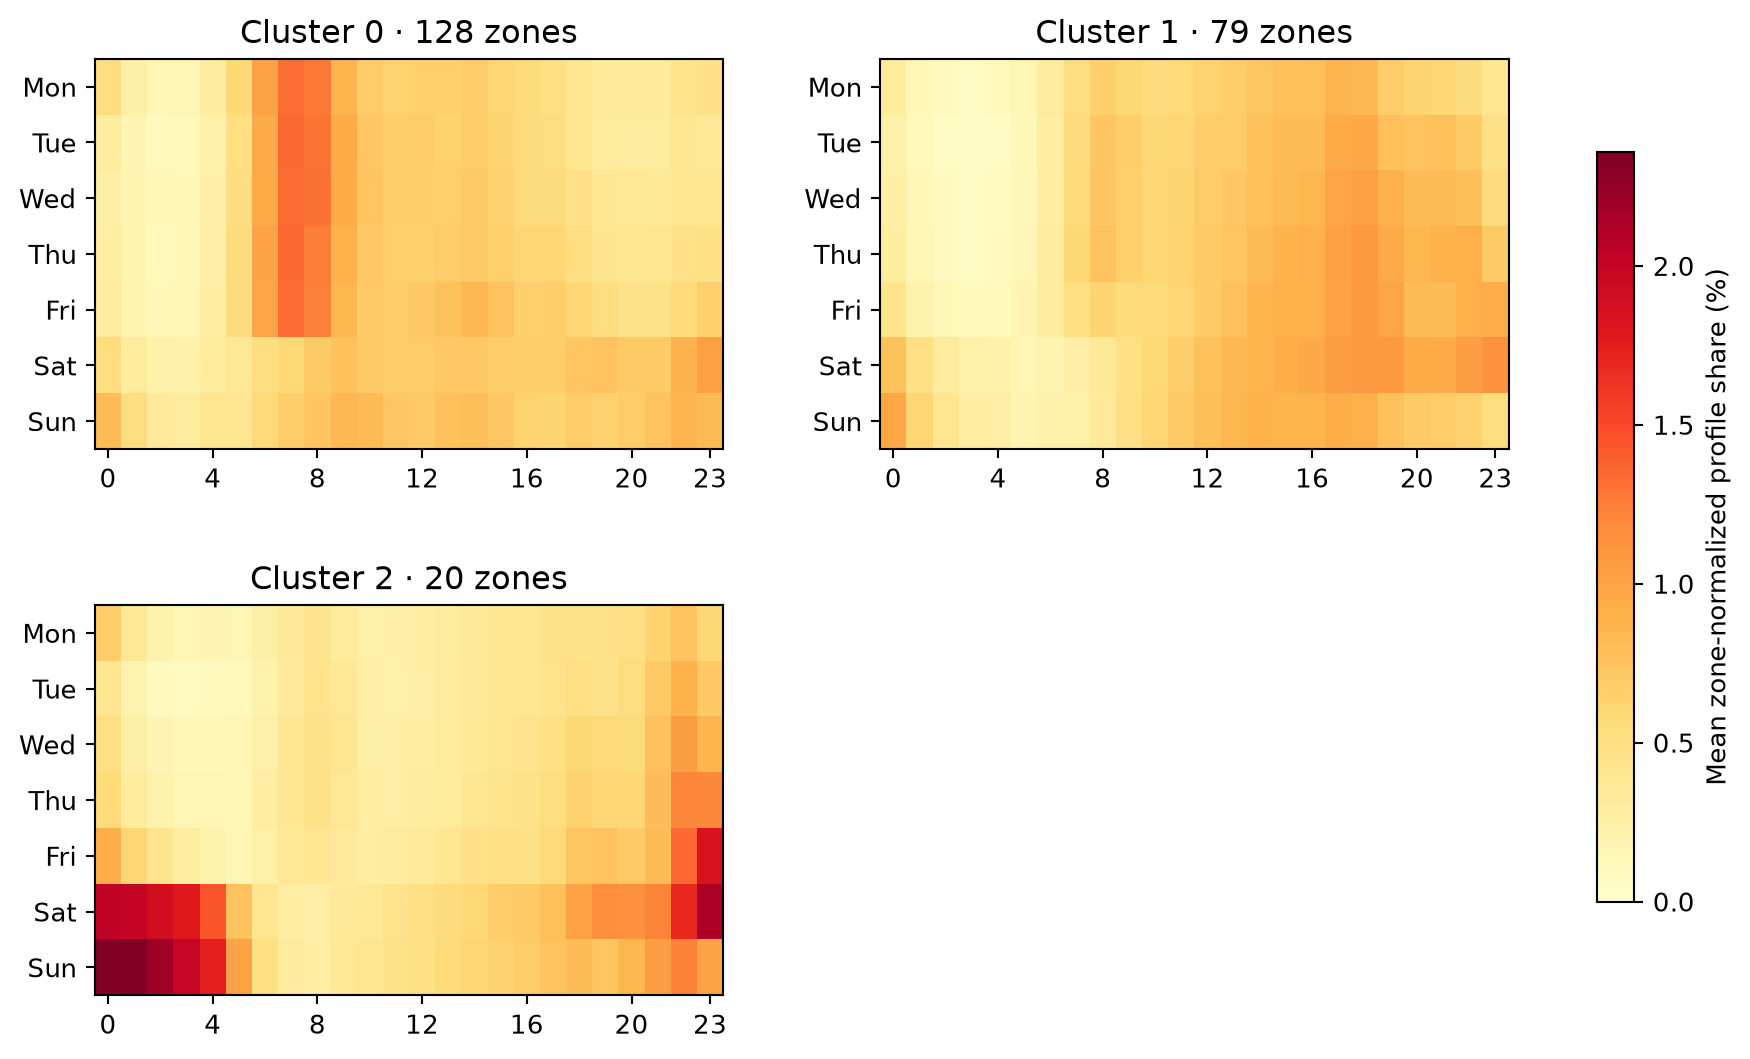

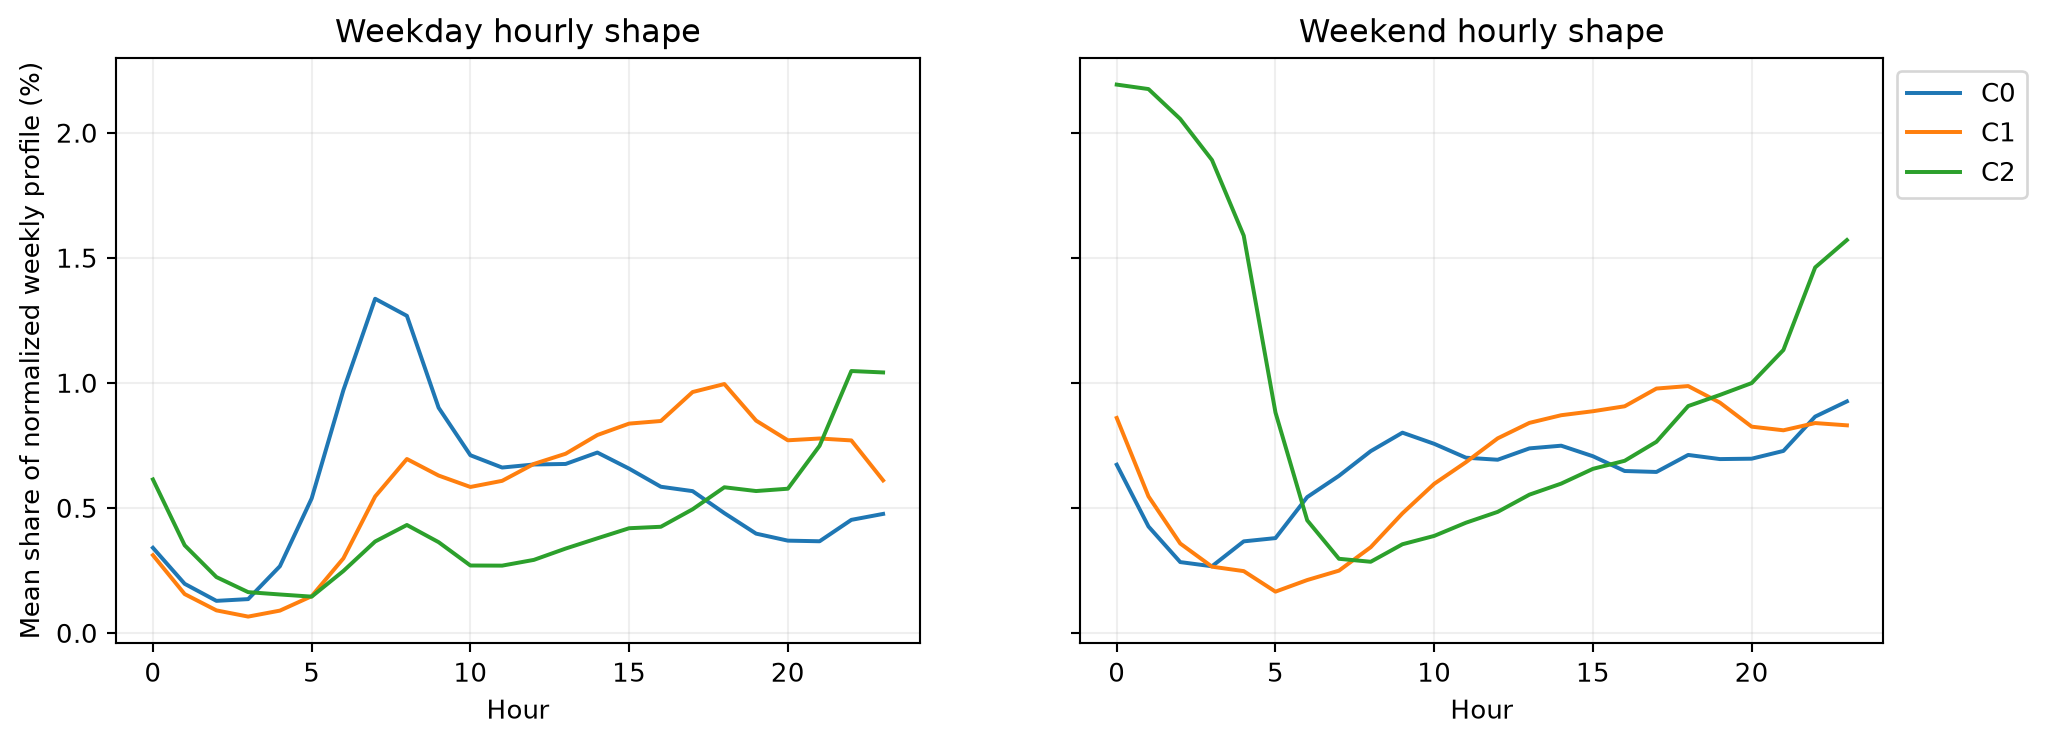

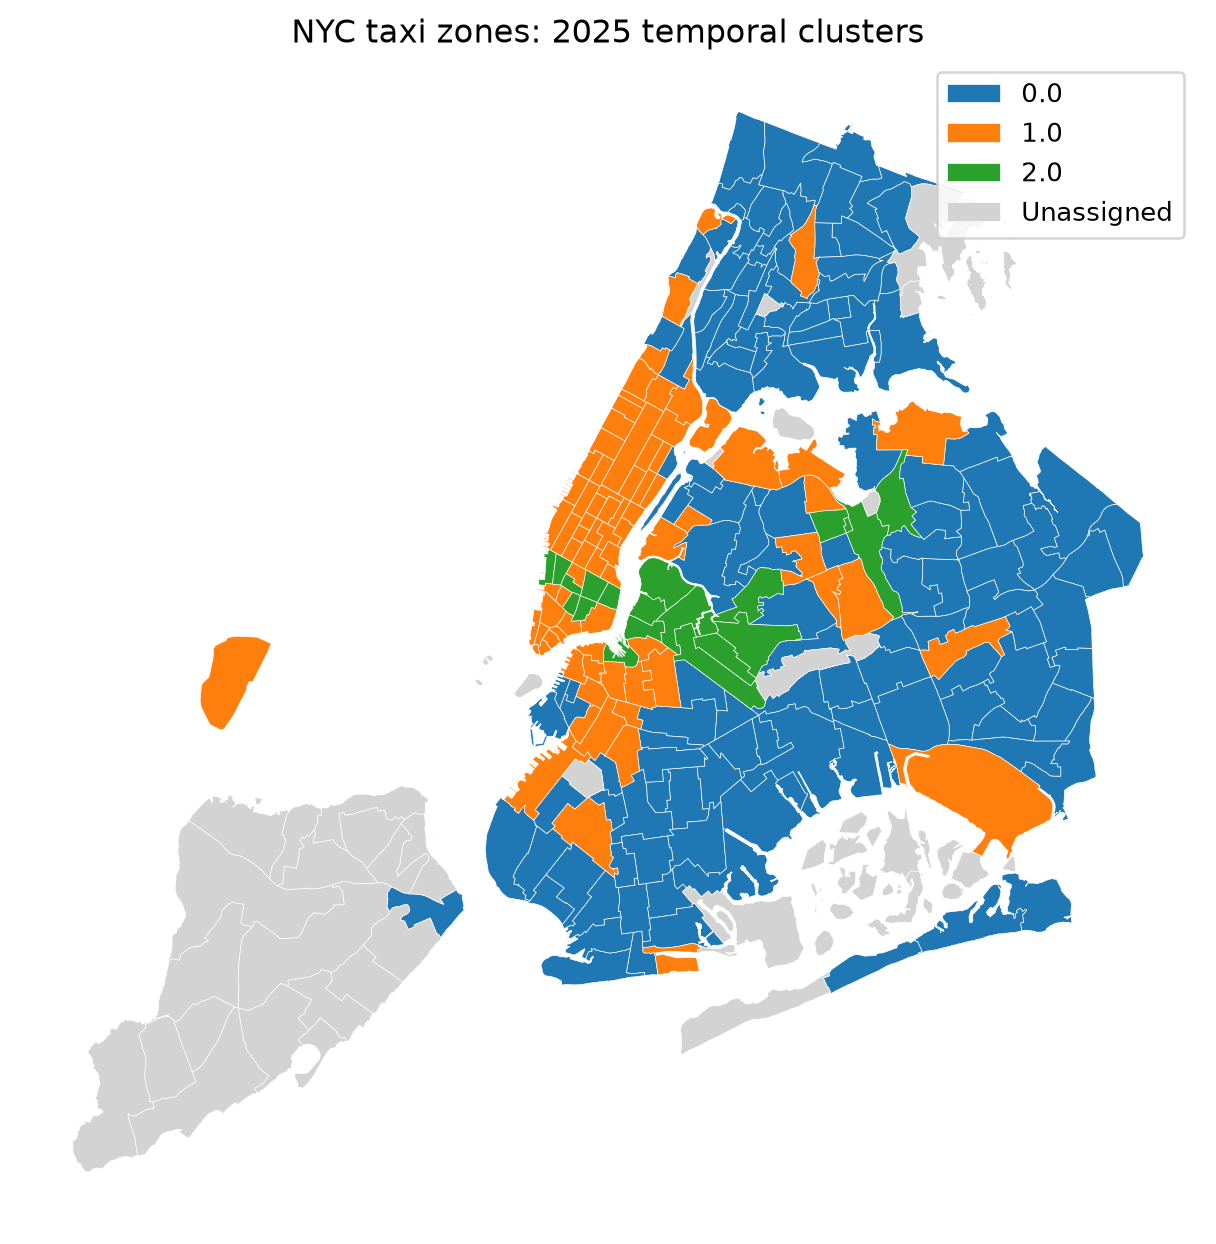

In [4]:
reps=pd.read_csv(TABLES/'cluster_representatives.csv')
display(reps)
for name in ['rq2_cluster_168d_heatmaps.png','rq2_cluster_time_curves.png','rq2_temporal_cluster_map.png']:
    p=FIGS/name
    if p.exists():display(Image(filename=str(p),width=800))


## 4. Compare RQ1 mobility communities vs RQ2 temporal clusters

RQ1 clusters are based on OD flow connectivity. RQ2 clusters are based on pickup demand shape. ARI/AMI and the contingency table tell whether they align on the **same eligible geographic zones**. They do not imply causality.

,community_id,cluster_id,n_zones,pct_within_community
0,0,0,0,0.000000
1,0,1,26,0.787879
2,0,2,7,0.212121
3,1,0,121,0.746914
4,1,1,28,0.172840
5,1,2,13,0.080247
6,2,0,7,0.218750
7,2,1,25,0.781250
8,2,2,0,0.000000


Agreement metrics: {'n_shared_zones': 227, 'ARI': 0.3290320734739484, 'AMI': 0.2725786610346454}


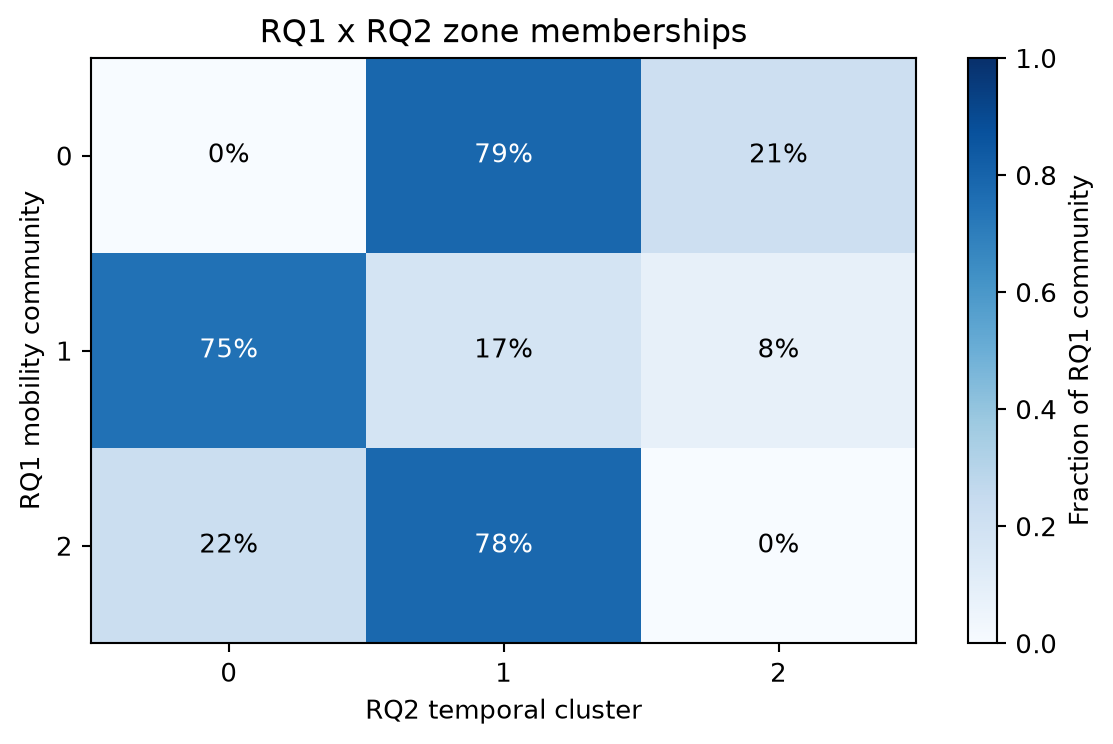

In [5]:
p=TABLES/'community_cluster_crosstab.csv'
if p.exists():
    display(pd.read_csv(p))
    print('Agreement metrics:',cluster_meta.get('rq1_rq2_agreement'))
    picture=FIGS/'rq1_rq2_overlap.png'
    if picture.exists(): display(Image(filename=str(picture),width=620))
else: print('Optional RQ1 comparison unavailable: check results/network/tables/communities_annual.csv')


## 5. Notes for the final report

Record: (i) included Pickup-valid records and DST policy, (ii) 263×168 profile construction, (iii) row normalization and zero-zone handling, (iv) PCA dimensions / cumulative variance, (v) selected K, silhouette and smallest cluster, (vi) cluster peak times, representative zones and NYC map, (vii) seed stability, (viii) descriptive RQ1/RQ2 ARI/AMI, (ix) limitation that Yellow Taxi demand is not full urban mobility.

**Leakage warning:** these cluster labels use full-year 2025 demand. Do *not* feed them into 2025 forecasting as historical features.